                                     SARIMAX Results                                      
Dep. Variable:                                  y   No. Observations:                35078
Model:             SARIMAX(1, 0, 1)x(0, 1, 1, 24)   Log Likelihood              -56578.223
Date:                            Tue, 23 Jun 2026   AIC                         113178.447
Time:                                    14:29:06   BIC                         113271.550
Sample:                                01-01-2020   HQIC                        113208.101
                                     - 01-01-2024                                         
Covariance Type:                              opg                                         
                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
PM10                      0.0833      0.001    127.469      0.000       0.082       0.085
SO

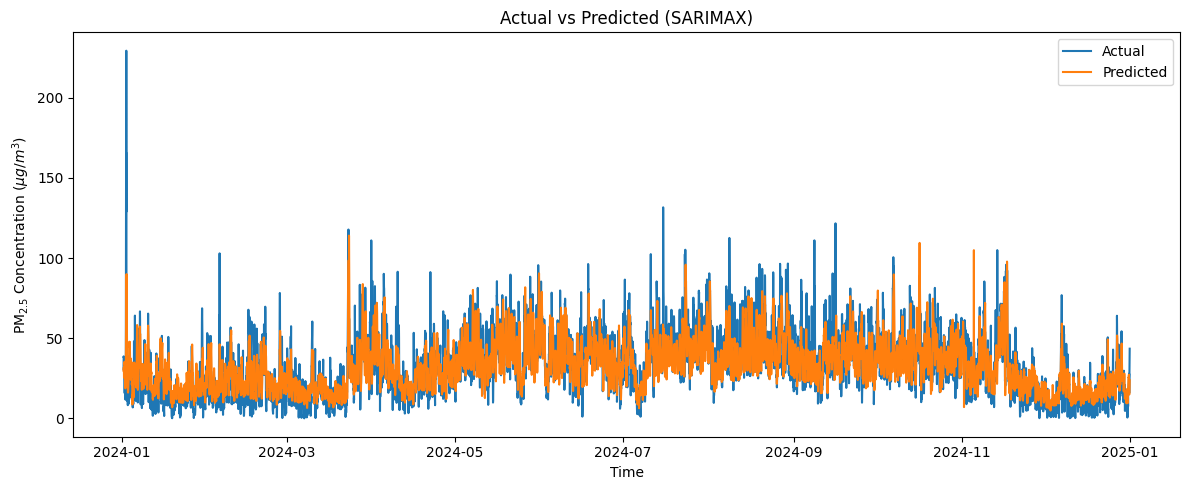

Fitting 5 folds for each of 96 candidates, totalling 480 fits

===== BEST PARAMETER =====
{'C': 20, 'epsilon': 0.001, 'gamma': 0.01}
Best CV RMSE = 0.0180

===== HASIL EVALUASI =====
  Dataset     RMSE     MAE      R2
0   Train  11.7330  7.9596  0.6182
1    Test  13.5983  8.7945  0.4778


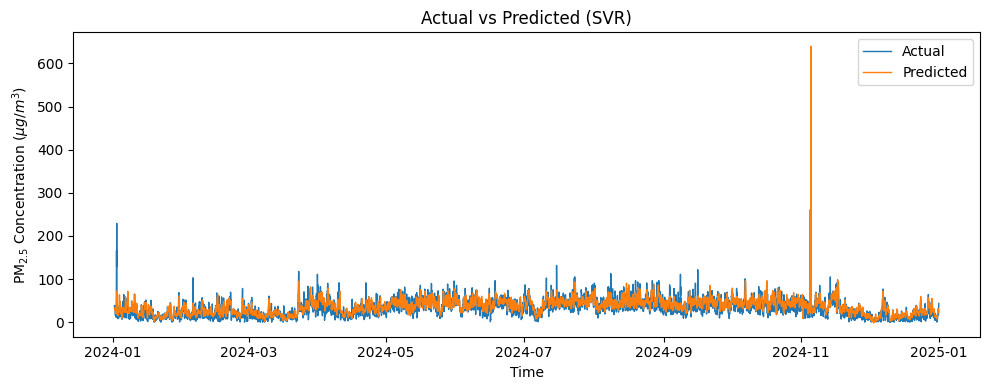


Jumlah data train : 35078
Jumlah data test  : 8770
Alpha SARIMAX = 0.80
Beta SVR      = 0.20

=== TRAIN ===
RMSE : 8.704586230587516
MAE  : 5.3292882881854275
R2   : 0.7898465359583309

=== TEST ===
RMSE : 11.796909353905962
MAE  : 8.713748772748476
R2   : 0.6070054403840814


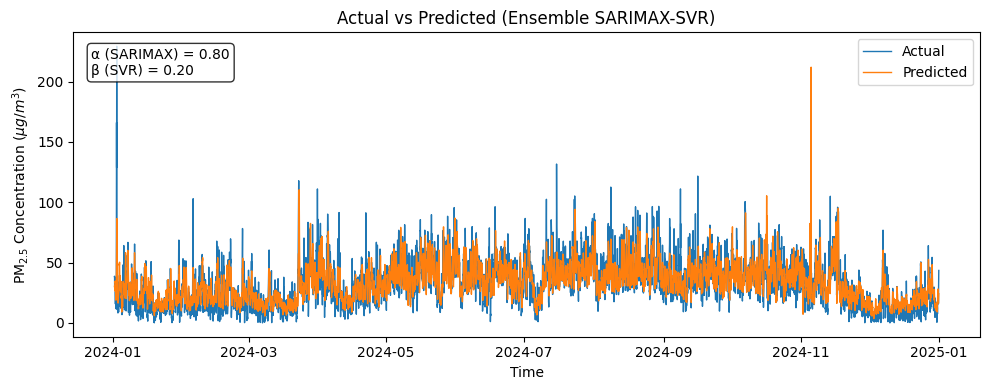

In [ ]:
import pandas as pd
import numpy as np
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.preprocessing import PowerTransformer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")

# =========================
# 1. Load data
# =========================
df_path = "/content/drive/MyDrive/Model/Data Imputasi 2/Data Final Konsentrasi Meteorologi DKI1 Bundaran HI.xlsx"
df = pd.read_excel(df_path, parse_dates=['datetime'], index_col='datetime')

y = df['PM2.5'].values.reshape(-1, 1)

X = df[['PM10','SO2','CO','O3','NO2',
        'Suhu Udara (°C)',
        'Kecepatan Angin (m/s)']]

# =========================
# 2. Train-test split
# =========================
train_size = int(len(df) * 0.8)

y_train_raw = y[:train_size]
y_test_raw  = y[train_size:]

exog_train = X.iloc[:train_size]
exog_test  = X.iloc[train_size:]

# =========================
# 3. Box-Cox transform
# =========================
if np.any(y_train_raw <= 0):
    y_shift = np.abs(np.min(y_train_raw)) + 1
else:
    y_shift = 0

y_train_pos = y_train_raw + y_shift
y_test_pos  = y_test_raw  + y_shift

pt = PowerTransformer(method='box-cox', standardize=False)

y_train = pt.fit_transform(y_train_pos)
y_test  = pt.transform(y_test_pos)

# =========================
# 4. Fit SARIMAX
# =========================
order = (1, 0, 1)
seasonal_order = (0, 1, 1, 24)

model = SARIMAX(
    y_train.flatten(),
    exog=exog_train,
    order=order,
    seasonal_order=seasonal_order,
    enforce_stationarity=False,
    enforce_invertibility=False
)

result = model.fit(disp=False)
print(result.summary())

# =========================
# 5. Prediksi
# =========================
pred_train = result.predict(
    start=0,
    end=len(y_train)-1,
    exog=exog_train
)

pred_test = result.predict(
    start=len(y_train),
    end=len(y_train)+len(y_test)-1,
    exog=exog_test
)

# =========================
# 6. Inverse Box-Cox
# =========================
pred_train_inv = pt.inverse_transform(
    pred_train.to_numpy().reshape(-1, 1)
).flatten() - y_shift

pred_test_inv = pt.inverse_transform(
    pred_test.to_numpy().reshape(-1, 1)
).flatten() - y_shift

y_train_inv = pt.inverse_transform(y_train).flatten() - y_shift
y_test_inv  = pt.inverse_transform(y_test).flatten() - y_shift

# =========================
# 7. Evaluasi
# =========================
def print_metrics(true, pred, label=""):
    mask = ~np.isnan(true) & ~np.isnan(pred)
    true_clean = true[mask]
    pred_clean = pred[mask]

    print(f"\n=== {label} ===")
    print("MAE :", mean_absolute_error(true_clean, pred_clean))
    print("RMSE:", np.sqrt(mean_squared_error(true_clean, pred_clean)))
    print("R2  :", r2_score(true_clean, pred_clean))

print_metrics(y_train_inv, pred_train_inv, "Train")
print_metrics(y_test_inv, pred_test_inv, "Test")

# =========================
# 8. Plot hasil
# =========================
plt.figure(figsize=(12,5))

plt.plot(df.index[train_size:], y_test_inv, label='Actual')
plt.plot(df.index[train_size:], pred_test_inv, label='Predicted')

plt.title('Actual vs Predicted (SARIMAX)')
plt.ylabel(r'PM$_{2.5}$ Concentration ($\mu g/m^3$)')
plt.xlabel('Time')
plt.legend(loc='upper right')

plt.tight_layout()
plt.savefig(
    '/content/drive/MyDrive/Gambar/PDF Gambar/Bundaran HI/SARIMAX_test.pdf',
    dpi=600,
    bbox_inches='tight',
    format='pdf'
)
plt.show()

# =====================================================
# SIMPAN HASIL SARIMAX SEBELUM MASUK KE BLOK SVR
# =====================================================

sarimax_train_pred = pred_train_inv.copy()
sarimax_test_pred  = pred_test_inv.copy()

y_train_actual = y_train_raw.flatten()
y_test_actual  = y_test_raw.flatten()

# ===============================
# IMPORT LIBRARY
# ===============================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# ===============================
# LOAD DATA
# ===============================
df_path = "/content/drive/MyDrive/Model/Data Imputasi 2/Data Final Konsentrasi Meteorologi DKI1 Bundaran HI.xlsx"

df = pd.read_excel(
    df_path,
    parse_dates=['datetime'],
    index_col='datetime'
)

# Target
y = df['PM2.5']

# Variabel input
X = df[['PM10',
        'SO2',
        'CO',
        'O3',
        'NO2',
        'Suhu Udara (°C)',
        'Kecepatan Angin (m/s)']]

# ===============================
# TRAIN TEST SPLIT
# ===============================
train_size = int(len(df) * 0.8)

X_train = X.iloc[:train_size]
X_test  = X.iloc[train_size:]

y_train = y.iloc[:train_size]
y_test  = y.iloc[train_size:]

# ===============================
# SCALING
# ===============================
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled  = scaler_X.transform(X_test)

y_train_scaled = scaler_y.fit_transform(
    y_train.values.reshape(-1,1)
).ravel()

y_test_scaled = scaler_y.transform(
    y_test.values.reshape(-1,1)
).ravel()

# ===============================
# HYPERPARAMETER TUNING
# ===============================
tscv = TimeSeriesSplit(n_splits=5)

param_grid = {
    'C': [10, 12, 14, 16, 18, 20],
    'gamma': [0.001, 0.004, 0.007, 0.01],
    'epsilon': [0.0001, 0.0004, 0.0007, 0.001]
}

grid = GridSearchCV(
    estimator=SVR(kernel='rbf'),
    param_grid=param_grid,
    cv=tscv,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
    verbose=2
)

grid.fit(
    X_train_scaled,
    y_train_scaled
)

# ===============================
# BEST PARAMETER
# ===============================
print("\n===== BEST PARAMETER =====")
print(grid.best_params_)
print(f"Best CV RMSE = {-grid.best_score_:.4f}")

svr = grid.best_estimator_

# ===============================
# PREDIKSI
# ===============================
pred_train_scaled = svr.predict(X_train_scaled)
pred_test_scaled  = svr.predict(X_test_scaled)

# ===============================
# INVERSE SCALING
# ===============================
pred_train_inv = scaler_y.inverse_transform(
    pred_train_scaled.reshape(-1,1)
).flatten()

pred_test_inv = scaler_y.inverse_transform(
    pred_test_scaled.reshape(-1,1)
).flatten()

y_train_inv = scaler_y.inverse_transform(
    y_train_scaled.reshape(-1,1)
).flatten()

y_test_inv = scaler_y.inverse_transform(
    y_test_scaled.reshape(-1,1)
).flatten()

# ===============================
# EVALUASI TRAIN
# ===============================
train_rmse = np.sqrt(
    mean_squared_error(
        y_train_inv,
        pred_train_inv
    )
)

train_mae = mean_absolute_error(
    y_train_inv,
    pred_train_inv
)

train_r2 = r2_score(
    y_train_inv,
    pred_train_inv
)

# ===============================
# EVALUASI TEST
# ===============================
test_rmse = np.sqrt(
    mean_squared_error(
        y_test_inv,
        pred_test_inv
    )
)

test_mae = mean_absolute_error(
    y_test_inv,
    pred_test_inv
)

test_r2 = r2_score(
    y_test_inv,
    pred_test_inv
)

# ===============================
# HASIL EVALUASI
# ===============================
hasil = pd.DataFrame({
    'Dataset': ['Train', 'Test'],
    'RMSE': [train_rmse, test_rmse],
    'MAE': [train_mae, test_mae],
    'R2': [train_r2, test_r2]
})

print("\n===== HASIL EVALUASI =====")
print(hasil.round(4))

# ===============================
# PLOT TEST SET ONLY
# ===============================
plt.figure(figsize=(10,4))

plt.plot(
    df.index[train_size:],
    y_test_inv,
    label='Actual',
    linewidth=1
)

plt.plot(
    df.index[train_size:],
    pred_test_inv,
    label='Predicted',
    linewidth=1
)

plt.title('Actual vs Predicted (SVR)')
plt.ylabel(r'PM$_{2.5}$ Concentration ($\mu g/m^3$)')
plt.xlabel('Time')
plt.legend(loc='upper right')

plt.tight_layout()

plt.savefig(
    '/content/drive/MyDrive/Gambar/PDF Gambar/Bundaran HI/SVR_test.pdf',
    dpi=600,
    bbox_inches='tight',
    format='pdf'
)

plt.show()

# ===============================
# SIMPAN HASIL PREDIKSI
# ===============================
svr_train_pred = pd.Series(
    pred_train_inv,
    index=X_train.index
)

svr_test_pred = pd.Series(
    pred_test_inv,
    index=X_test.index
)

print("\nJumlah data train :", len(svr_train_pred))
print("Jumlah data test  :", len(svr_test_pred))

# =====================================================
# PASTIKAN TIDAK ADA NaN / INF
# =====================================================

mask_train = (
    np.isfinite(y_train_actual) &
    np.isfinite(sarimax_train_pred) &
    np.isfinite(svr_train_pred)
)

y_train_ens = y_train_actual[mask_train]
sarimax_train_ens = sarimax_train_pred[mask_train]
svr_train_ens = svr_train_pred[mask_train]

# =====================================================
# CARI BOBOT TERBAIK
# =====================================================

best_rmse = np.inf
best_alpha = 0

for alpha in np.arange(0, 1.01, 0.1):

    beta = 1 - alpha

    ensemble_train = (
        alpha * sarimax_train_ens +
        beta * svr_train_ens
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_train_ens,
            ensemble_train
        )
    )

    if rmse < best_rmse:
        best_rmse = rmse
        best_alpha = alpha

best_beta = 1 - best_alpha

print(f"Alpha SARIMAX = {best_alpha:.2f}")
print(f"Beta SVR      = {best_beta:.2f}")

# =====================================================
# ENSEMBLE TRAIN
# =====================================================

ensemble_train = (
    best_alpha * sarimax_train_ens +
    best_beta * svr_train_ens
)

# =====================================================
# ENSEMBLE TEST
# =====================================================

mask_test = (
    np.isfinite(y_test_actual) &
    np.isfinite(sarimax_test_pred) &
    np.isfinite(svr_test_pred)
)

y_test_ens = y_test_actual[mask_test]
sarimax_test_ens = sarimax_test_pred[mask_test]
svr_test_ens = svr_test_pred[mask_test]

ensemble_test = (
    best_alpha * sarimax_test_ens +
    best_beta * svr_test_ens
)

# =====================================================
# EVALUASI
# =====================================================

print("\n=== TRAIN ===")
print("RMSE :", np.sqrt(mean_squared_error(
    y_train_ens,
    ensemble_train
)))
print("MAE  :", mean_absolute_error(
    y_train_ens,
    ensemble_train
))
print("R2   :", r2_score(
    y_train_ens,
    ensemble_train
))

print("\n=== TEST ===")
print("RMSE :", np.sqrt(mean_squared_error(
    y_test_ens,
    ensemble_test
)))
print("MAE  :", mean_absolute_error(
    y_test_ens,
    ensemble_test
))
print("R2   :", r2_score(
    y_test_ens,
    ensemble_test
))
# =====================================================
# INDEX UNTUK PLOT
# =====================================================

train_index = df.index[:train_size][mask_train]
test_index  = df.index[train_size:][mask_test]

# =====================================================
# PLOT TEST SET ONLY - ENSEMBLE SARIMAX-SVR
# =====================================================

plt.figure(figsize=(10,4))

textstr = (
    f'α (SARIMAX) = {best_alpha:.2f}\n'
    f'β (SVR) = {best_beta:.2f}'
)

plt.plot(
    test_index,
    y_test_ens,
    label='Actual',
    linewidth=1
)

plt.plot(
    test_index,
    ensemble_test,
    label='Predicted',
    linewidth=1
)

plt.title(
    'Actual vs Predicted (Ensemble SARIMAX-SVR)'
)

plt.ylabel(
    r'PM$_{2.5}$ Concentration ($\mu g/m^3$)'
)

plt.xlabel('Time')

plt.legend(loc='upper right')

plt.text(
    0.02,
    0.95,
    textstr,
    transform=plt.gca().transAxes,
    fontsize=10,
    verticalalignment='top',
    bbox=dict(
        boxstyle='round',
        facecolor='white',
        alpha=0.8
    )
)

plt.tight_layout()

plt.savefig(
    '/content/drive/MyDrive/Gambar/PDF Gambar/Bundaran HI/ensemble_SARIMAX_SVR_test.pdf',
    dpi=600,
    bbox_inches='tight',
    format='pdf'
)

plt.show()

                                     SARIMAX Results                                      
Dep. Variable:                                  y   No. Observations:                35078
Model:             SARIMAX(1, 0, 1)x(0, 1, 1, 24)   Log Likelihood              -56578.223
Date:                            Tue, 23 Jun 2026   AIC                         113178.447
Time:                                    23:26:56   BIC                         113271.550
Sample:                                01-01-2020   HQIC                        113208.101
                                     - 01-01-2024                                         
Covariance Type:                              opg                                         
                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
PM10                      0.0833      0.001    127.469      0.000       0.082       0.085
SO

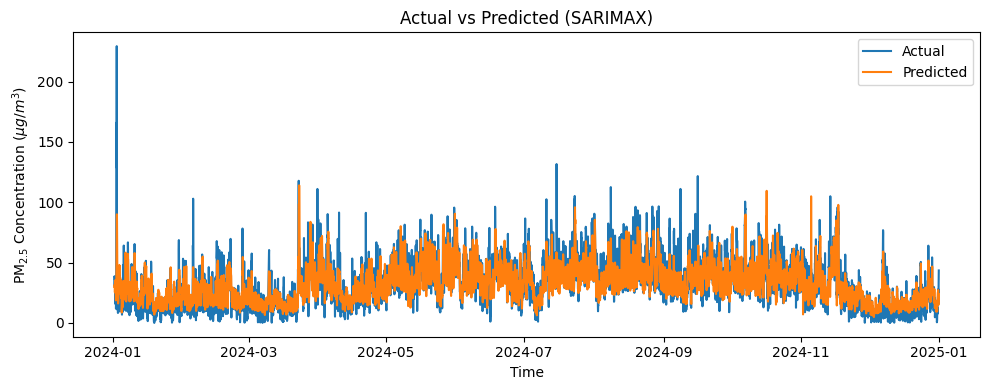

Fitting 5 folds for each of 30 candidates, totalling 150 fits
[LightGBM] [Warning] feature_fraction is set=0.9, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.9
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] feature_fraction is set=0.9, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.9
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002701 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2040
[LightGBM] [Info] Number of data points in the train set: 35077, number of used features: 8
[LightGBM] [Info] Start training from score 32.394331
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with

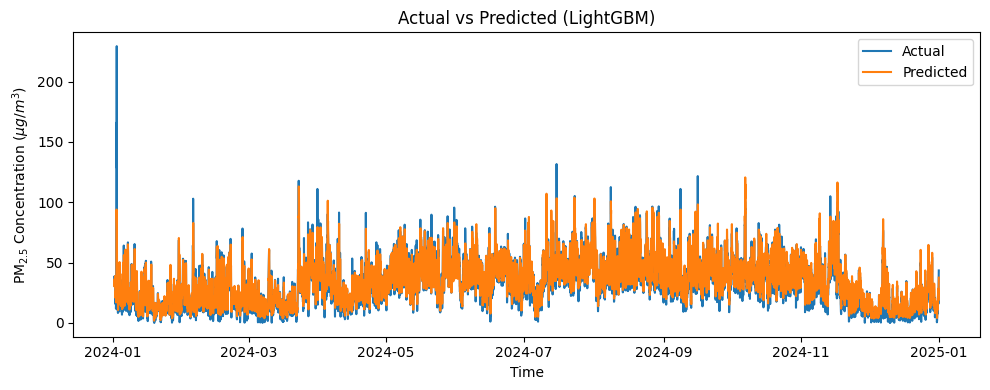


===== BOBOT TERBAIK =====
Alpha (SARIMAX) : 0.30000000000000004
Beta  (LGBM)    : 0.7

=== TRAIN ENSEMBLE ===
RMSE : 8.245901228992476
MAE  : 5.014057036188059
R²   : 0.8113929500697113

=== TEST ENSEMBLE ===
RMSE : 8.533284568900868
MAE  : 6.193543208477037
R²   : 0.7943718770533781


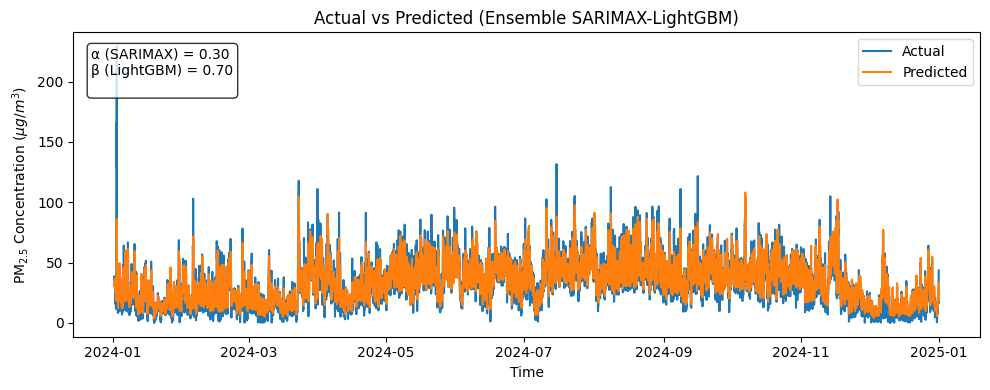

In [ ]:
import pandas as pd
import numpy as np
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.preprocessing import PowerTransformer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")

# =========================
# 1. Load data
# =========================
df_path = "/content/drive/MyDrive/Model/Data Imputasi 2/Data Final Konsentrasi Meteorologi DKI1 Bundaran HI.xlsx"
df = pd.read_excel(df_path, parse_dates=['datetime'], index_col='datetime')

y = df['PM2.5'].values.reshape(-1, 1)

X = df[['PM10','SO2','CO','O3','NO2',
        'Suhu Udara (°C)',
        'Kecepatan Angin (m/s)']]

# =========================
# 2. Train-test split
# =========================
train_size = int(len(df) * 0.8)

y_train_raw = y[:train_size]
y_test_raw  = y[train_size:]

exog_train = X.iloc[:train_size]
exog_test  = X.iloc[train_size:]

# =========================
# 3. Box-Cox transform
# =========================
if np.any(y_train_raw <= 0):
    y_shift = np.abs(np.min(y_train_raw)) + 1
else:
    y_shift = 0

y_train_pos = y_train_raw + y_shift
y_test_pos  = y_test_raw  + y_shift

pt = PowerTransformer(method='box-cox', standardize=False)

y_train = pt.fit_transform(y_train_pos)
y_test  = pt.transform(y_test_pos)

# =========================
# 4. Fit SARIMAX
# =========================
order = (1, 0, 1)
seasonal_order = (0, 1, 1, 24)

model = SARIMAX(
    y_train.flatten(),
    exog=exog_train,
    order=order,
    seasonal_order=seasonal_order,
    enforce_stationarity=False,
    enforce_invertibility=False
)

result = model.fit(disp=False)
print(result.summary())

# =========================
# 5. Prediksi
# =========================
pred_train = result.get_prediction(
    start=0,
    end=len(y_train)-1,
    exog=exog_train
).predicted_mean

pred_test = result.get_prediction(
    start=len(y_train),
    end=len(y_train)+len(y_test)-1,
    exog=exog_test
).predicted_mean

# =========================
# 6. Inverse Box-Cox
# =========================
pred_train_inv = pt.inverse_transform(
    pred_train.to_numpy().reshape(-1, 1)
).flatten() - y_shift

pred_test_inv = pt.inverse_transform(
    pred_test.to_numpy().reshape(-1, 1)
).flatten() - y_shift

y_train_inv = pt.inverse_transform(y_train).flatten() - y_shift
y_test_inv  = pt.inverse_transform(y_test).flatten() - y_shift

# =========================
# 7. Evaluasi
# =========================
def print_metrics(true, pred, label=""):
    mask = ~np.isnan(true) & ~np.isnan(pred)
    true_clean = true[mask]
    pred_clean = pred[mask]

    print(f"\n=== {label} ===")
    print("MAE :", mean_absolute_error(true_clean, pred_clean))
    print("RMSE:", np.sqrt(mean_squared_error(true_clean, pred_clean)))
    print("R2  :", r2_score(true_clean, pred_clean))

print_metrics(y_train_inv, pred_train_inv, "Train")
print_metrics(y_test_inv, pred_test_inv, "Test")

# =========================
# 8. Plot hasil
# =========================
plt.figure(figsize=(10,4))

plt.plot(df.index[train_size:], y_test_inv, label='Actual')
plt.plot(df.index[train_size:], pred_test_inv, label='Predicted')

plt.title('Actual vs Predicted (SARIMAX)')
plt.ylabel(r'PM$_{2.5}$ Concentration ($\mu g/m^3$)')
plt.xlabel('Time')
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()

# =====================================================
# SIMPAN HASIL SARIMAX
# =====================================================

sarimax_train_pred = pred_train_inv.copy()
sarimax_test_pred  = pred_test_inv.copy()

y_train_actual = y_train_raw.flatten()
y_test_actual  = y_test_raw.flatten()

# ===============================
# 1. IMPORT LIBRARY
# ===============================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from lightgbm import LGBMRegressor

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV

import warnings
warnings.filterwarnings("ignore")


# ===============================
# 2. LOAD DATA
# ===============================
df_path = "/content/drive/MyDrive/Model/Data Imputasi 2/Data Final Konsentrasi Meteorologi DKI1 Bundaran HI.xlsx"

df = pd.read_excel(
    df_path,
    parse_dates=['datetime'],
    index_col='datetime'
)

y = df['PM2.5']

X = df[[
    'PM10',
    'SO2',
    'CO',
    'O3',
    'NO2',
    'Suhu Udara (°C)',
    'Kecepatan Angin (m/s)',
]]


# ===============================
# 3. TIME SERIES SPLIT
# ===============================
train_size = int(len(df) * 0.8)

X_train, X_test = X.iloc[:train_size], X.iloc[train_size:]
y_train, y_test = y.iloc[:train_size], y.iloc[train_size:]


# ===============================
# 4. BASE MODEL
# ===============================
lgbm = LGBMRegressor(random_state=42)


# ===============================
# 5. PARAMETER
# ===============================
param_grid = {
    'max_depth': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    'num_leaves': [10, 12, 14, 16, 18, 20],
    'learning_rate': [0.01, 0.02, 0.03, 0.05],
    'n_estimators': [1000, 1200, 1500, 1800, 2000],
    'min_child_samples': [10, 20, 30, 40, 50],
    'subsample': [0.7, 0.8, 0.9],
    'feature_fraction': [0.5, 0.6, 0.7, 0.8, 0.9],
    'reg_alpha': [0.01, 0.02, 0.03, 0.04, 0.05],
    'reg_lambda': [0.1, 0.5, 1]
}


# ===============================
# 6. TIME SERIES CV
# ===============================
tscv = TimeSeriesSplit(n_splits=5)


# ===============================
# 7. RANDOM SEARCH CV
# ===============================
search = RandomizedSearchCV(
    estimator=lgbm,
    param_distributions=param_grid,
    n_iter=30,
    cv=tscv,
    scoring='neg_root_mean_squared_error',
    verbose=2,
    random_state=42,
    n_jobs=-1
)


# ===============================
# 8. TRAIN MODEL
# ===============================
search.fit(X_train, y_train)

best_model = search.best_estimator_

print("\n===== BEST PARAMETERS =====")
print(search.best_params_)


# ===============================
# 9. PREDICTION
# ===============================
lgbm_train_pred = best_model.predict(X_train)
lgbm_test_pred  = best_model.predict(X_test)


# ===============================
# 10. EVALUATION FUNCTION
# ===============================
def evaluate(y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    return rmse, mae, r2


train_rmse, train_mae, train_r2 = evaluate(y_train, lgbm_train_pred)
test_rmse, test_mae, test_r2 = evaluate(y_test, lgbm_test_pred)


# ===============================
# 11. RESULT TABLE
# ===============================
hasil = pd.DataFrame({
    'Dataset': ['Train', 'Test'],
    'RMSE': [train_rmse, test_rmse],
    'MAE': [train_mae, test_mae],
    'R2': [train_r2, test_r2]
})

print("\n===== HASIL EVALUASI =====")
print(hasil.round(4))


import matplotlib.pyplot as plt

plt.figure(figsize=(10,4))

plt.plot(
    y_test.index,
    y_test,
    label='Actual'
)

plt.plot(
    y_test.index,
    lgbm_test_pred,
    label='Predicted'
)

plt.title('Actual vs Predicted (LightGBM)')
plt.xlabel('Time')
plt.ylabel(r'PM$_{2.5}$ Concentration ($\mu g/m^3$)')
plt.legend(loc='upper right')

plt.tight_layout()

plt.savefig(
    '/content/drive/MyDrive/Gambar/PDF Gambar/Bundaran HI/LightGBM_test.pdf',
    dpi=600,
    bbox_inches='tight'
)

plt.show()

import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sarimax_train = sarimax_train_pred.copy()
sarimax_test  = sarimax_test_pred.copy()

lgbm_train = lgbm_train_pred.copy()
lgbm_test  = lgbm_test_pred.copy()

y_train_ens = y_train_actual.copy()
y_test_ens  = y_test_actual.copy()

min_train = min(
    len(sarimax_train),
    len(lgbm_train),
    len(y_train_ens)
)

min_test = min(
    len(sarimax_test),
    len(lgbm_test),
    len(y_test_ens)
)

sarimax_train = sarimax_train[-min_train:]
lgbm_train     = lgbm_train[-min_train:]
y_train_ens   = y_train_ens[-min_train:]

sarimax_test = sarimax_test[-min_test:]
lgbm_test     = lgbm_test[-min_test:]
y_test_ens   = y_test_ens[-min_test:]

mask_train = (
    ~np.isnan(sarimax_train) &
    ~np.isnan(lgbm_train) &
    ~np.isnan(y_train_ens)
)

sarimax_train = sarimax_train[mask_train]
lgbm_train    = lgbm_train[mask_train]
y_train_ens   = y_train_ens[mask_train]

train_datetime = X_train.index[-min_train:]
train_datetime = train_datetime[mask_train]

mask_test = (
    ~np.isnan(sarimax_test) &
    ~np.isnan(lgbm_test) &
    ~np.isnan(y_test_ens)
)

sarimax_test = sarimax_test[mask_test]
lgbm_test    = lgbm_test[mask_test]
y_test_ens   = y_test_ens[mask_test]

test_datetime = X_test.index[-min_test:]
test_datetime = test_datetime[mask_test]

# =====================================================
# CARI BOBOT TERBAIK
# =====================================================

best_rmse = np.inf
best_alpha = 0

for alpha in np.arange(0, 1.01, 0.1):

    beta = 1 - alpha

    pred_train = (
        alpha * sarimax_train +
        beta  * lgbm_train
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_train_ens,
            pred_train
        )
    )

    if rmse < best_rmse:
        best_rmse = rmse
        best_alpha = alpha

best_beta = 1 - best_alpha

print("\n===== BOBOT TERBAIK =====")
print("Alpha (SARIMAX) :", best_alpha)
print("Beta  (LGBM)    :", best_beta)

# =====================================================
# ENSEMBLE PREDICTION
# =====================================================

ensemble_train = (
    best_alpha * sarimax_train +
    best_beta  * lgbm_train
)

ensemble_test = (
    best_alpha * sarimax_test +
    best_beta  * lgbm_test
)

# =====================================================
# EVALUASI
# =====================================================

def evaluate(y_true, y_pred, label=""):

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    r2 = r2_score(
        y_true,
        y_pred
    )

    print(f"\n=== {label} ===")
    print("RMSE :", rmse)
    print("MAE  :", mae)
    print("R²   :", r2)

evaluate(
    y_train_ens,
    ensemble_train,
    "TRAIN ENSEMBLE"
)

evaluate(
    y_test_ens,
    ensemble_test,
    "TEST ENSEMBLE"
)

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10,4))

textstr = (
    f'α (SARIMAX) = {best_alpha:.2f}\n'
    f'β (LightGBM) = {best_beta:.2f}\n'
)

ax.plot(
    test_datetime,
    y_test_ens,
    label='Actual'
)

ax.plot(
    test_datetime,
    ensemble_test,
    label='Predicted'
)

ax.set_title('Actual vs Predicted (Ensemble SARIMAX-LightGBM)')
ax.set_xlabel('Time')
ax.set_ylabel(r'PM$_{2.5}$ Concentration ($\mu g/m^3$)')
ax.legend(loc='upper right')

ax.text(
    0.02, 0.95,
    textstr,
    transform=ax.transAxes,
    fontsize=10,
    verticalalignment='top',
    bbox=dict(boxstyle='round', facecolor='white', alpha=0.8)
)

plt.tight_layout()

plt.savefig(
    '/content/drive/MyDrive/Gambar/PDF Gambar/Bundaran HI/ensemble_SARIMAX_LightGBM_test.pdf',
    dpi=600,
    bbox_inches='tight'
)

plt.show()